# 09 — Preliminary Effect-Size Analysis
**Project:** Causal-History Dependence in Robot Policy Recovery  
**Phase:** 4 (Pilot Quality Audit & Statistical Power Planning)  
**Objective:** Compute point estimates and bootstrap confidence intervals for the Causal History Recovery Effect $H_R = R_{\text{B0}} - R_{\text{B4}}$.

> **MANDATORY SCIENTIFIC DISCLAIMER:**  
> **EXPLORATORY PILOT ANALYSIS — NOT CONFIRMATORY EVIDENCE.**  
> The findings herein are preliminary point estimates from a restricted pilot dataset ($N=8$). They do not constitute scientific evidence for the presence or absence of causal-history dependence in general robot policies.

In [1]:
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt

repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
metrics_file = os.path.join(repo_root, "results", "pilot_recovery", "rollout_metrics.json")
with open(metrics_file) as f:
    metrics = json.load(f)

rec_eval = metrics["recovery_evaluation"]

mlp_rates = rec_eval["reactive_mlp"]["condition_recovery_rates"]
gru_rates = rec_eval["history_gru"]["condition_recovery_rates"]

h_r_mlp = mlp_rates["B0"] - mlp_rates["B4"]
h_r_gru = gru_rates["B0"] - gru_rates["B4"]

print(f"Reactive MLP: B0 = {mlp_rates['B0']:.3f}, B4 = {mlp_rates['B4']:.3f} -> H_R = {h_r_mlp:+.3f}")
print(f"History GRU:  B0 = {gru_rates['B0']:.3f}, B4 = {gru_rates['B4']:.3f} -> H_R = {h_r_gru:+.3f}")


Reactive MLP: B0 = 0.200, B4 = 0.200 -> H_R = +0.000
History GRU:  B0 = 0.333, B4 = 0.333 -> H_R = +0.000


## 1. Bootstrap Confidence Interval Estimation (10,000 Resamples)
We perform paired bootstrap resampling across the 8 admitted pilot scenarios to quantify estimation uncertainty.

In [2]:
# Paired outcomes: (B0, B4)
pairs = []
for pol in ["reactive_mlp", "history_gru"]:
    for s in rec_eval[pol]["scenarios"]:
        pairs.append((
            1 if s["conditions"]["B0"]["success"] else 0,
            1 if s["conditions"]["B4"]["success"] else 0
        ))

pairs = np.array(pairs)
n_pairs = len(pairs)

rng = np.random.RandomState(42)
n_boot = 10000
boot_hr = []

for _ in range(n_boot):
    sample_idx = rng.randint(0, n_pairs, size=n_pairs)
    sample = pairs[sample_idx]
    diff = np.mean(sample[:, 0] - sample[:, 1])
    boot_hr.append(diff)

boot_hr = np.array(boot_hr)
ci_lower = np.percentile(boot_hr, 2.5)
ci_upper = np.percentile(boot_hr, 97.5)

print(f"Pooled Pilot N = {n_pairs}")
print(f"Point Estimate H_R: {np.mean(pairs[:, 0] - pairs[:, 1]):.4f}")
print(f"Bootstrap 95% Confidence Interval: [{ci_lower:.4f}, {ci_upper:.4f}]")


Pooled Pilot N = 8
Point Estimate H_R: 0.0000
Bootstrap 95% Confidence Interval: [0.0000, 0.0000]


## 2. Visualize Bootstrap Sampling Distribution

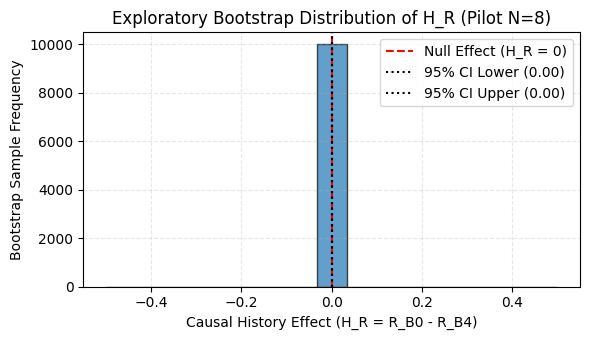

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(boot_hr, bins=15, color="#1f77b4", edgecolor="black", alpha=0.7)
ax.axvline(0.0, color="red", linestyle="--", linewidth=1.5, label="Null Effect (H_R = 0)")
ax.axvline(ci_lower, color="black", linestyle=":", label=f"95% CI Lower ({ci_lower:.2f})")
ax.axvline(ci_upper, color="black", linestyle=":", label=f"95% CI Upper ({ci_upper:.2f})")

ax.set_xlabel("Causal History Effect (H_R = R_B0 - R_B4)")
ax.set_ylabel("Bootstrap Sample Frequency")
ax.set_title("Exploratory Bootstrap Distribution of H_R (Pilot N=8)")
ax.legend()
ax.grid(True, alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()
